# 2. Полиномиальная регрессия. Регуляризация. Кросс-валидация.

In [1]:
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

SEED = 42
DEGREES = np.arange(16)
LAMBDAS = np.r_[0.0, np.logspace(-10, 1, 24)]
N_TRAIN, N_TEST, N_FOLDS = 30, 1000, 5

OUT = Path.cwd()
if (OUT / 'Lab2_Polynomial_Regression').is_dir():
    OUT = OUT / 'Lab2_Polynomial_Regression'
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110})

functions = [
    ('cos', 'cos(x)', np.cos),
    ('cubic', '5x³ + x² + 5', lambda x: 5*x**3 + x**2 + 5),
    ('xsin', 'x sin(x)', lambda x: x*np.sin(x)),
]
noise_names = {'uniform': 'равномерный', 'normal': 'нормальный'}
x_grid = np.linspace(0, 2*np.pi, 1000)


def show_table(headers, rows):
    lines = [' | '.join(headers), ' | '.join(['---'] * len(headers))]
    lines += [' | '.join(map(str, row)) for row in rows]
    display(Markdown('\n'.join(lines)))


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=180, bbox_inches='tight')
    plt.show()

## 1. Выборки и шум

Генерируем $x_i\sim U[0,2\pi]$, $y_i=f(x_i)+\varepsilon_i$.
Для каждой функции задаём $\sigma=0.1\,\mathrm{std}(f(x_{grid}))$.
Это параметр **генератора**, позволяющий исследовать функции разных масштабов.
Нормальный шум: $N(0,\sigma^2)$. Равномерный: $U[-\sqrt3\sigma,\sqrt3\sigma]$.

In [2]:
datasets = []
for function_id, (key, label, f) in enumerate(functions):
    rng_x = np.random.default_rng(SEED + function_id)
    x_train = rng_x.uniform(0, 2*np.pi, N_TRAIN)
    x_test = rng_x.uniform(0, 2*np.pi, N_TEST)
    sigma = 0.1 * np.std(f(x_grid))

    for noise_id, noise_kind in enumerate(noise_names):
        rng = np.random.default_rng(SEED + 100 + 10*function_id + noise_id)
        if noise_kind == 'uniform':
            error = rng.uniform(-np.sqrt(3)*sigma, np.sqrt(3)*sigma, N_TRAIN + N_TEST)
        else:
            error = rng.normal(0, sigma, N_TRAIN + N_TEST)

        datasets.append(dict(
            key=key, label=label, f=f, noise=noise_kind, sigma=sigma,
            x=x_train.copy(), y=f(x_train) + error[:N_TRAIN],
            x_test=x_test.copy(), y_test=f(x_test) + error[N_TRAIN:],
        ))

show_table(['Функция', 'σ', 'Обучение', 'Тест'],
           [[d['label'], f"{d['sigma']:.4g}", N_TRAIN, N_TEST] for d in datasets[::2]])

Функция | σ | Обучение | Тест
--- | --- | --- | ---
cos(x) | 0.07075 | 30 | 1000
5x³ + x² + 5 | 36.37 | 30 | 1000
x sin(x) | 0.2308 | 30 | 1000

## 2. Метод наименьших квадратов и Ridge

Используем $t=(x-\pi)/\pi\in[-1,1]$ и $p_M(x)=\sum_{j=0}^M w_jt^j$.
Это тот же класс полиномов по x. Масштабирование уменьшает численные проблемы
при больших степенях. Матрица признаков $\Phi_{ij}=t_i^j$.

Минимизируем
$$J(w)=\frac{1}{2n}\|\Phi w-y\|_2^2+
\frac{\lambda}{2}\sum_{j=1}^M w_j^2.$$
При $\lambda=0$ получаем обычный МНК. Свободный коэффициент $w_0$ не штрафуем.
Не вычисляем обратную матрицу $\Phi^T\Phi$: решаем задачу через `np.linalg.lstsq`.
Для Ridge добавляем строки $\sqrt{n\lambda}D$, где $D=\mathrm{diag}(0,1,\ldots,1)$.

Регуляризация зависит от базиса: здесь штрафуются коэффициенты степеней t,
а не исходных степеней x. Все значения λ ниже относятся к этой формуле.

In [3]:
def design_matrix(x, degree):
    t = (np.asarray(x) - np.pi) / np.pi
    return np.vander(t, N=degree + 1, increasing=True)


def fit_polynomial(x, y, degree, lam=0.0):
    phi = design_matrix(x, degree)
    if lam == 0:
        return np.linalg.lstsq(phi, y, rcond=None)[0]

    penalty = np.eye(degree + 1)
    penalty[0, 0] = 0  # свободный коэффициент не регуляризуется
    A = np.vstack([phi, np.sqrt(len(x)*lam) * penalty])
    b = np.r_[y, np.zeros(degree + 1)]
    return np.linalg.lstsq(A, b, rcond=None)[0]


def predict(x, weights):
    return design_matrix(x, len(weights) - 1) @ weights


def rmse(y, prediction):
    return np.sqrt(np.mean((np.asarray(y) - prediction)**2))

## 3. Кросс-валидация

Перемешиваем индексы 30 обучающих точек и делим на 5 частей.
Каждая часть один раз служит валидационной, остальные четыре — обучающими.
Складываем квадраты ошибок всех отложенных предсказаний и делим на 30.
Изучаем M=0…15 и λ=0 плюс 24 положительных значения от $10^{-10}$ до 10.
Разбиения одинаковы для всех моделей.

Выбираем отдельно лучший МНК (λ=0), лучшую Ridge-модель (λ>0)
и лучшую Ridge-модель при фиксированном M=15. Последняя нужна для проверки,
что именно регуляризация помогает переобученному полиному высокой степени.

In [4]:
indices = np.random.default_rng(SEED).permutation(N_TRAIN)
folds = np.array_split(indices, N_FOLDS)


def cross_validation(x, y, degree, lam):
    squared_error = 0.0
    for valid_idx in folds:
        train_idx = np.setdiff1d(np.arange(len(x)), valid_idx)
        weights = fit_polynomial(x[train_idx], y[train_idx], degree, lam)
        squared_error += np.sum((y[valid_idx] - predict(x[valid_idx], weights))**2)
    return np.sqrt(squared_error / len(x))


for d in datasets:
    scores = np.empty((len(DEGREES), len(LAMBDAS)))
    train_errors = []
    for i, degree in enumerate(DEGREES):
        weights = fit_polynomial(d['x'], d['y'], degree)
        train_errors.append(rmse(d['y'], predict(d['x'], weights)))
        for j, lam in enumerate(LAMBDAS):
            scores[i, j] = cross_validation(d['x'], d['y'], degree, lam)

    best_ols = int(np.argmin(scores[:, 0]))
    i, j = np.unravel_index(np.argmin(scores[:, 1:]), scores[:, 1:].shape)
    j += 1
    j15 = 1 + int(np.argmin(scores[15, 1:]))
    d.update(scores=scores, train_errors=np.array(train_errors),
             best_ols=best_ols, best_ridge=(int(i), int(j)), ridge15=j15)

print('Рассчитаны 6 выборок, 16 степеней и 25 значений lambda.')

Рассчитаны 6 выборок, 16 степеней и 25 значений lambda.


## 4. Как проявляется переобучение

Показаны обучающая ошибка и ошибка кросс-валидации МНК.
Ошибки делим на $\sigma$, чтобы сравнивать функции разного масштаба.
Уменьшение обучающей ошибки при одновременном росте CV-ошибки указывает на переобучение.
Логарифмическая шкала позволяет увидеть большие ошибки полиномов высокой степени.

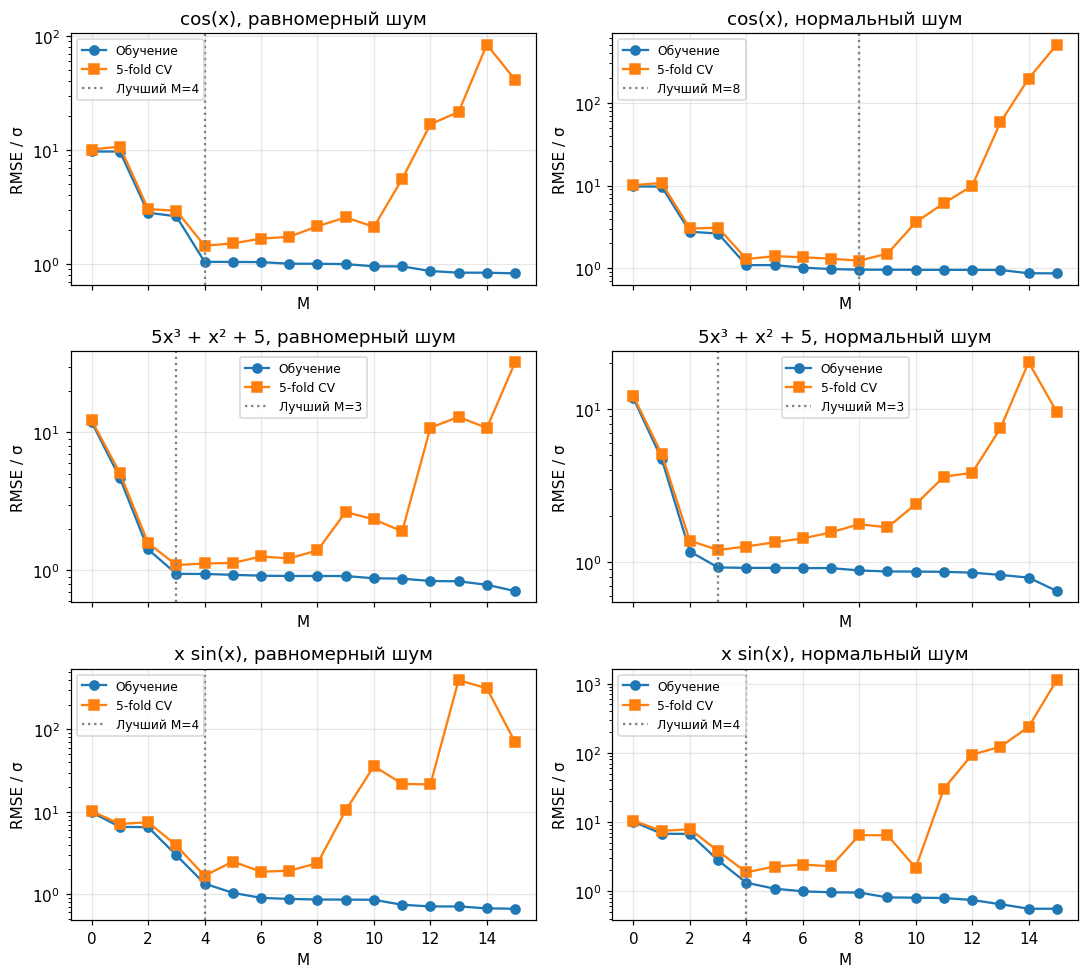

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(10, 9), sharex=True)
for ax, d in zip(axes.flat, datasets):
    ax.semilogy(DEGREES, d['train_errors']/d['sigma'], 'o-', label='Обучение')
    ax.semilogy(DEGREES, d['scores'][:, 0]/d['sigma'], 's-', label='5-fold CV')
    ax.axvline(d['best_ols'], color='gray', ls=':', label=f"Лучший M={d['best_ols']}")
    ax.set(title=f"{d['label']}, {noise_names[d['noise']]} шум", xlabel='M', ylabel='RMSE / σ')
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
save_figure('01_degree_errors.png')

## 5. Итоговая оценка выбранных моделей

После выбора параметров обучаем модели заново на всех 30 обучающих точках.
**RMSE test** измеряется по независимым шумным наблюдениям.
**RMSE f** - ошибка относительно точной функции на равномерной сетке из 1000 точек;
это дополнительная диагностика восстановления зависимости, а не критерий выбора.
Даже точная функция имеет ожидаемый MSE по шумным данным, равный σ².

In [6]:
results = []
for d in datasets:
    i, j = d['best_ridge']
    candidates = [
        ('МНК CV', d['best_ols'], 0),
        ('Ridge CV', i, j),
        ('МНК M=15', 15, 0),
        ('Ridge M=15', 15, d['ridge15']),
    ]
    d['models'] = {}
    for method, degree, lambda_index in candidates:
        lam = float(LAMBDAS[lambda_index])
        weights = fit_polynomial(d['x'], d['y'], degree, lam)
        row = dict(function=d['key'], noise=d['noise'], method=method,
                   M=int(degree), lam=lam,
                   cv=float(d['scores'][degree, lambda_index]),
                   train=float(rmse(d['y'], predict(d['x'], weights))),
                   test=float(rmse(d['y_test'], predict(d['x_test'], weights))),
                   truth=float(rmse(d['f'](x_grid), predict(x_grid, weights))))
        results.append(row)
        d['models'][method] = dict(weights=weights, **row)

show_table(['Функция', 'Шум', 'Метод', 'M', 'λ', 'RMSE CV', 'RMSE test', 'RMSE f'],
           [[r['function'], noise_names[r['noise']], r['method'], r['M'],
             f"{r['lam']:.2g}", f"{r['cv']:.4g}", f"{r['test']:.4g}", f"{r['truth']:.4g}"]
            for r in results])

with (OUT / 'results.csv').open('w', newline='', encoding='utf-8-sig') as file:
    writer = csv.DictWriter(file, fieldnames=list(results[0]))
    writer.writeheader()
    writer.writerows(results)
(OUT / 'results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')

Функция | Шум | Метод | M | λ | RMSE CV | RMSE test | RMSE f
--- | --- | --- | --- | --- | --- | --- | ---
cos | равномерный | МНК CV | 4 | 0 | 0.1023 | 0.0746 | 0.02388
cos | равномерный | Ridge CV | 4 | 0.00016 | 0.1008 | 0.07541 | 0.02884
cos | равномерный | МНК M=15 | 15 | 0 | 2.926 | 0.8452 | 0.8737
cos | равномерный | Ridge M=15 | 15 | 0.0015 | 0.1382 | 0.1237 | 0.1012
cos | нормальный | МНК CV | 8 | 0 | 0.08771 | 0.1116 | 0.09577
cos | нормальный | Ridge CV | 8 | 7.4e-08 | 0.08768 | 0.1109 | 0.09475
cos | нормальный | МНК M=15 | 15 | 0 | 35.7 | 0.773 | 0.7918
cos | нормальный | Ridge M=15 | 15 | 1.8e-05 | 0.09505 | 0.1436 | 0.1361
cubic | равномерный | МНК CV | 3 | 0 | 39.77 | 37.22 | 12.45
cubic | равномерный | Ridge CV | 3 | 0.0015 | 39.66 | 37.31 | 12.53
cubic | равномерный | МНК M=15 | 15 | 0 | 1170 | 70.27 | 61.81
cubic | равномерный | Ridge M=15 | 15 | 0.0015 | 44.55 | 38.96 | 16.31
cubic | нормальный | МНК CV | 3 | 0 | 43.51 | 37.8 | 9.407
cubic | нормальный | Ridge CV | 3 | 1.8e-05 | 43.51 | 37.79 | 9.395
cubic | нормальный | МНК M=15 | 15 | 0 | 346.8 | 57.66 | 47.29
cubic | нормальный | Ridge M=15 | 15 | 0.00016 | 53.39 | 38.17 | 11.51
xsin | равномерный | МНК CV | 4 | 0 | 0.385 | 0.3433 | 0.2606
xsin | равномерный | Ridge CV | 14 | 1e-10 | 0.3607 | 0.7002 | 0.6892
xsin | равномерный | МНК M=15 | 15 | 0 | 16.23 | 1.137 | 1.279
xsin | равномерный | Ridge M=15 | 15 | 0.0015 | 0.5751 | 0.4313 | 0.361
xsin | нормальный | МНК CV | 4 | 0 | 0.4294 | 0.3237 | 0.2402
xsin | нормальный | Ridge CV | 11 | 8.2e-09 | 0.3812 | 0.3223 | 0.2479
xsin | нормальный | МНК M=15 | 15 | 0 | 260.6 | 1.142 | 1.29
xsin | нормальный | Ridge M=15 | 15 | 6.7e-07 | 0.4203 | 0.345 | 0.2854

5929

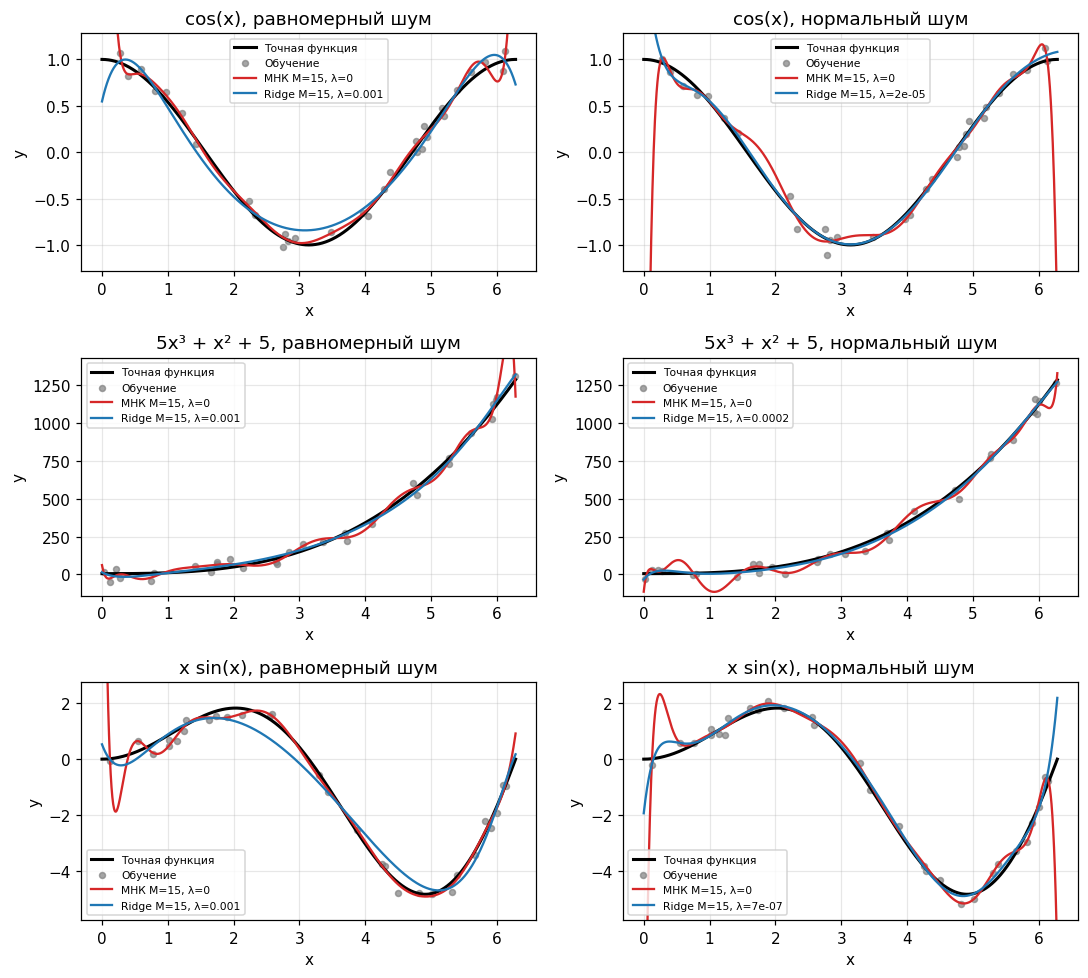

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(10, 9))
for ax, d in zip(axes.flat, datasets):
    ax.plot(x_grid, d['f'](x_grid), 'k', lw=2, label='Точная функция')
    ax.scatter(d['x'], d['y'], s=15, color='gray', alpha=.7, label='Обучение')
    for method, color in [('МНК M=15', 'tab:red'), ('Ridge M=15', 'tab:blue')]:
        model = d['models'][method]
        ax.plot(x_grid, predict(x_grid, model['weights']), color=color,
                label=f"{method}, λ={model['lam']:.1g}")
    # Ограничиваем только видимую область, метрики считаются без отсечения.
    y_true = d['f'](x_grid)
    ax.set_ylim(y_true.min() - 4*d['sigma'], y_true.max() + 4*d['sigma'])
    ax.set(title=f"{d['label']}, {noise_names[d['noise']]} шум", xlabel='x', ylabel='y')
    ax.grid(alpha=.3)
    ax.legend(fontsize=7)
save_figure('02_regularization.png')

## 6. Пример для cos(x) с нормальным шумом

Разберём одну выборку: сравним недообученный полином M=1, переобученный M=15
и Ridge-модель с M и λ, выбранными по CV. На правом графике виден подбор λ
при фиксированной степени 15. Тестовые ошибки не используются в этом подборе.

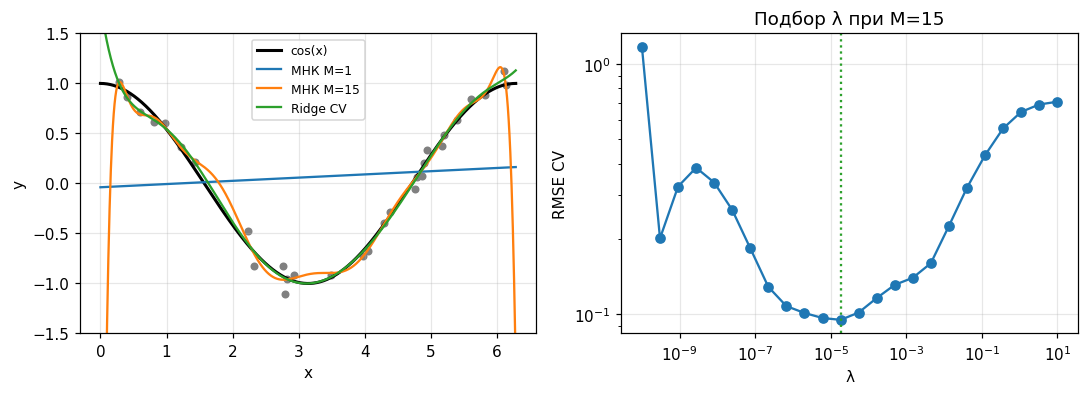

Выбрано **M=8**, **λ=7.406e-08**, RMSE test=0.1109, RMSE f=0.09475.

j | Коэффициент при t^j
--- | ---
0 | -0.99984
1 | 0.0756609
2 | 4.78847
3 | -1.65312
4 | -1.82635
5 | 4.94994
6 | -4.88554
7 | -3.70209
8 | 4.38282

In [8]:
example = next(d for d in datasets if d['key'] == 'cos' and d['noise'] == 'normal')
best = example['models']['Ridge CV']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
ax = axes[0]
ax.plot(x_grid, np.cos(x_grid), 'k', lw=2, label='cos(x)')
ax.scatter(example['x'], example['y'], s=18, color='gray')
for degree, lam, label in [(1, 0, 'МНК M=1'), (15, 0, 'МНК M=15'),
                           (best['M'], best['lam'], 'Ridge CV')]:
    w = fit_polynomial(example['x'], example['y'], degree, lam)
    ax.plot(x_grid, predict(x_grid, w), label=label)
ax.set(xlabel='x', ylabel='y', ylim=(-1.5, 1.5))
ax.legend(fontsize=8)
ax = axes[1]
ax.loglog(LAMBDAS[1:], example['scores'][15, 1:], 'o-')
ax.axvline(LAMBDAS[example['ridge15']], ls=':', color='tab:green')
ax.set(xlabel='λ', ylabel='RMSE CV', title='Подбор λ при M=15')
for ax in axes:
    ax.grid(alpha=.3)
save_figure('03_example.png')
display(Markdown(f"Выбрано **M={best['M']}**, **λ={best['lam']:.4g}**, "
                 f"RMSE test={best['test']:.4g}, RMSE f={best['truth']:.4g}."))
show_table(['j', 'Коэффициент при t^j'],
           [[j, f'{w:.6g}'] for j, w in enumerate(best['weights'])])

## 7. Задание 4 — геометрия ЛАССО

В ЛАССО к квадратичной ошибке $E(w)$ добавляют штраф за сумму модулей коэффициентов
$$F(w)=E(w)+\alpha\sum_j|w_j|,\qquad \alpha>0.$$

**Когда коэффициент обнуляется.** Зафиксируем остальные коэффициенты и обозначим через $g_j$ частную производную ошибки $E$ по $w_j$ в точке $w_j=0$. Тогда ноль минимизирует $F$ по этой координате тогда и только тогда, когда $|g_j|\leq\alpha$.

Действительно, в нуле левая производная $F$ по $w_j$ равна $g_j-\alpha$, а правая равна $g_j+\alpha$. У выпуклой функции минимум в нуле достигается, если левая производная неположительна, а правая неотрицательна. Отсюда получаем $-\alpha\leq g_j\leq\alpha$. Поэтому целый интервал значений производной ошибки соответствует нулевому коэффициенту.

**Геометрия.** Для двух коэффициентов ограничение $|w_1|+|w_2|\leq r$ задаёт ромб. Если минимум МНК лежит вне ромба, решение даёт первое касание линии уровня ошибки с его границей. В вершине одна координата равна нулю. Внутри ребра обе координаты ненулевые.

При полном столбцовом ранге матрицы признаков $\Phi$ линии уровня квадратичной ошибки имеют центр в решении МНК $\hat w$. Это следует из равенства
$$E(w)=E(\hat w)+\frac{1}{2n}\|\Phi(w-\hat w)\|_2^2.$$
На рисунке взят частный случай $E(w)=\frac12\|w-a\|_2^2$, где линии уровня — окружности с центром $a$.

В этом примере $g_j=-a_j$. При $|a_j|\leq\alpha$ условие обнуления выполнено. При $|a_j|>\alpha$ значение находим из условия нулевой производной.
$$w_j=\begin{cases}0, & |a_j|\leq\alpha,\\ a_j-\alpha\,\operatorname{sign}(a_j), & |a_j|>\alpha.\end{cases}$$
Обе ветви объединяет формула мягкого порога
$$w_j=\operatorname{sign}(a_j)\max(|a_j|-\alpha,0).$$
При $\alpha=1$ она даёт $(1,1)$ для $a=(2,2)$ и $(2,0)$ для $a=(3,0.4)$. Эти точки показаны на левой и правой панелях соответственно.

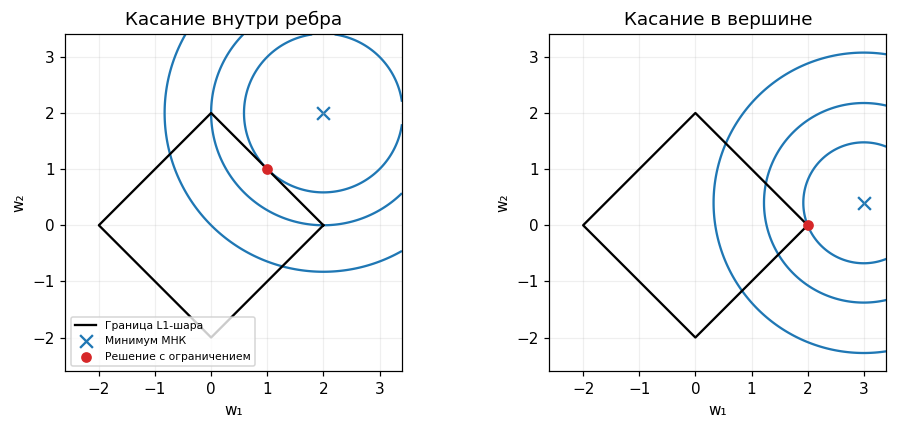

a = [2. 2.] α = 1.0 решение ЛАССО = [1. 1.]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
u = np.linspace(-2.6, 3.4, 400)
W1, W2 = np.meshgrid(u, u)
for ax, center, solution, title in zip(
        axes, [(2, 2), (3, .4)], [(1, 1), (2, 0)],
        ['Касание внутри ребра', 'Касание в вершине']):
    E = .5*((W1-center[0])**2 + (W2-center[1])**2)
    touch = .5*np.sum((np.array(solution)-center)**2)
    ax.contour(W1, W2, E, levels=[touch, touch+1, touch+3], colors='tab:blue')
    ax.plot([2, 0, -2, 0, 2], [0, 2, 0, -2, 0], 'k-', label='Граница L1-шара')
    ax.scatter(*center, marker='x', s=70, label='Минимум МНК')
    ax.scatter(*solution, color='tab:red', zorder=5, label='Решение с ограничением')
    ax.set(title=title, xlabel='w₁', ylabel='w₂', aspect='equal', xlim=(-2.6, 3.4), ylim=(-2.6, 3.4))
    ax.grid(alpha=.2)
axes[0].legend(fontsize=7, loc='lower left')
save_figure('04_lasso_geometry.png')
чё
# Численный пример мягкого порога: два ненулевых коэффициента.
a, alpha = np.array([2.0, 2.0]), 1.0
w_lasso = np.sign(a) * np.maximum(np.abs(a) - alpha, 0)
print('a =', a, 'α =', alpha, 'решение ЛАССО =', w_lasso)